In [1]:
# ============================================================
# NOTEBOOK 12
# Learning-Based Localization Reliability Prediction
# ============================================================

from pathlib import Path

import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.linear_model import LinearRegression

from IPython.display import display

plt.rcParams["figure.figsize"] = (10,6)

In [2]:
# ============================================================
# Cell 2
# Load Adaptive EKF Results
# ============================================================

PROJECT_ROOT = Path(
    r"D:\Research\Papers\Paper_2"
)

RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR = PROJECT_ROOT / "figures"

MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(exist_ok=True)

DRIVE = "2011_09_26_drive_0001_sync"

ekf = pd.read_csv(

    RESULT_DIR /

    f"adaptive_ekf_results_{DRIVE}.csv"

)

print("="*80)

print("Adaptive EKF Dataset Loaded")

print("="*80)

print("Shape :", ekf.shape)

display(ekf.head())

Adaptive EKF Dataset Loaded
Shape : (108, 18)


,Frame,X,Y,Velocity,Heading,Acceleration,Yaw Rate,Camera Weight,GPS Weight,IMU Weight,Localization Reliability Score,Estimated X,Estimated Y,Estimated Velocity,Estimated Heading,Innovation Norm,Covariance Trace,Position Error
0,0,0.000000,0.000000,13.173300,-2.608707,10.219657,-0.017909,0.148592,0.306539,0.544869,0.725692,-0.709538,-0.417884,13.140990,-2.610230,1.317330,2.663884,0.823451
1,1,-1.236488,-0.743110,13.130515,-2.611005,10.094229,-0.021380,0.086228,0.328993,0.584779,0.705164,-1.879174,-1.117098,13.115874,-2.608872,1.192215,2.786419,0.743580
2,2,-2.357236,-1.415460,13.085745,-2.613314,9.906112,-0.022716,0.056135,0.431708,0.512156,0.679463,-3.002804,-1.789760,13.088537,-2.608715,1.202951,2.870192,0.746229
3,3,-3.475952,-2.081099,13.042246,-2.615904,10.102561,-0.024292,0.092445,0.420070,0.487484,0.642736,-4.123053,-2.455799,13.063116,-2.610025,1.218973,2.972100,0.747756
4,4,-4.703593,-2.809404,12.996151,-2.618804,10.034660,-0.027261,0.148710,0.333678,0.517612,0.663197,-5.278805,-3.141559,13.049083,-2.611713,1.109771,2.957643,0.664226


In [3]:
# ============================================================
# Cell 3
# Machine Learning Dataset
# ============================================================

FEATURES = [

    "Velocity",

    "Heading",

    "Acceleration",

    "Yaw Rate",

    "Camera Weight",

    "GPS Weight",

    "IMU Weight",

    "Innovation Norm",

    "Covariance Trace"

]

TARGET = "Localization Reliability Score"

ml_data = ekf[

    FEATURES + [TARGET]

].copy()

ml_data = ml_data.dropna()

print("="*80)

print("Machine Learning Dataset")

print("="*80)

print()

print("Features")

for feature in FEATURES:

    print("-", feature)

print()

print("Target :", TARGET)

print()

print("Samples :", len(ml_data))

display(ml_data.head())

Machine Learning Dataset

Features
- Velocity
- Heading
- Acceleration
- Yaw Rate
- Camera Weight
- GPS Weight
- IMU Weight
- Innovation Norm
- Covariance Trace

Target : Localization Reliability Score

Samples : 108


,Velocity,Heading,Acceleration,Yaw Rate,Camera Weight,GPS Weight,IMU Weight,Innovation Norm,Covariance Trace,Localization Reliability Score
0,13.173300,-2.608707,10.219657,-0.017909,0.148592,0.306539,0.544869,1.317330,2.663884,0.725692
1,13.130515,-2.611005,10.094229,-0.021380,0.086228,0.328993,0.584779,1.192215,2.786419,0.705164
2,13.085745,-2.613314,9.906112,-0.022716,0.056135,0.431708,0.512156,1.202951,2.870192,0.679463
3,13.042246,-2.615904,10.102561,-0.024292,0.092445,0.420070,0.487484,1.218973,2.972100,0.642736
4,12.996151,-2.618804,10.034660,-0.027261,0.148710,0.333678,0.517612,1.109771,2.957643,0.663197


,Velocity,Heading,Acceleration,Yaw Rate,Camera Weight,GPS Weight,IMU Weight,Innovation Norm,Covariance Trace,Localization Reliability Score
Velocity,1.000000,0.777491,-0.057156,-0.822930,-0.624752,0.653681,-0.242511,-0.986424,-0.770385,-0.194988
Heading,0.777491,1.000000,0.023571,-0.800242,-0.412717,0.362713,-0.065646,-0.676086,-0.914633,-0.458603
Acceleration,-0.057156,0.023571,1.000000,0.093924,0.086582,-0.047344,-0.025560,0.088390,0.044541,0.007863
Yaw Rate,-0.822930,-0.800242,0.093924,1.000000,0.379162,-0.538086,0.340591,0.765672,0.768914,0.332869
Camera Weight,-0.624752,-0.412717,0.086582,0.379162,1.000000,-0.686676,-0.103853,0.644841,0.357893,0.266476
GPS Weight,0.653681,0.362713,-0.047344,-0.538086,-0.686676,1.000000,-0.651720,-0.689701,-0.392004,-0.230223
IMU Weight,-0.242511,-0.065646,-0.025560,0.340591,-0.103853,-0.651720,1.000000,0.270833,0.162920,0.036957
Innovation Norm,-0.986424,-0.676086,0.088390,0.765672,0.644841,-0.689701,0.270833,1.000000,0.699652,0.137922
Covariance Trace,-0.770385,-0.914633,0.044541,0.768914,0.357893,-0.392004,0.162920,0.699652,1.000000,0.290888
Localization Reliability Score,-0.194988,-0.458603,0.007863,0.332869,0.266476,-0.230223,0.036957,0.137922,0.290888,1.000000


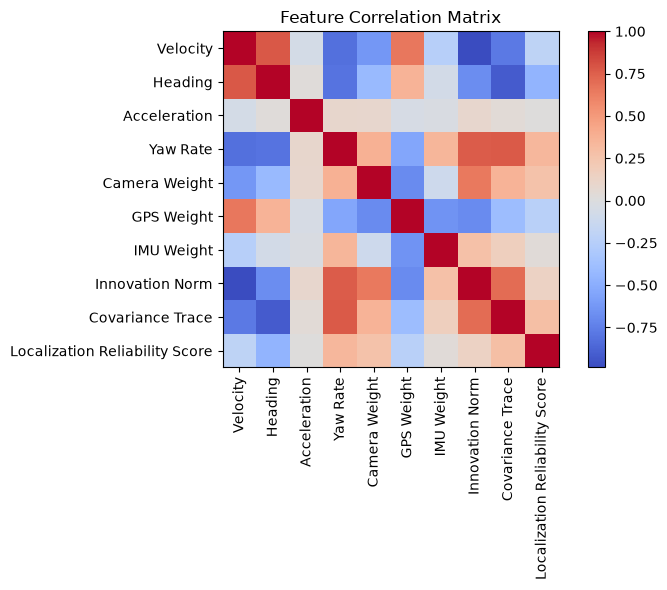

In [4]:
# ============================================================
# Cell 4
# Feature Correlation
# ============================================================

correlation = ml_data.corr()

display(correlation)

plt.figure(figsize=(8,6))

plt.imshow(

    correlation,

    cmap="coolwarm",

    interpolation="nearest"

)

plt.xticks(

    range(len(correlation.columns)),

    correlation.columns,

    rotation=90

)

plt.yticks(

    range(len(correlation.columns)),

    correlation.columns

)

plt.colorbar()

plt.title(

    "Feature Correlation Matrix"

)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "feature_correlation_matrix.png",

    dpi=300

)

plt.show()

In [5]:
# ============================================================
# Cell 5
# Train Test Split
# ============================================================

X = ml_data[FEATURES]

y = ml_data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    shuffle=True

)

print("="*80)

print("Training Samples :", len(X_train))

print("Testing Samples  :", len(X_test))

print("="*80)

Training Samples : 86
Testing Samples  : 22


In [6]:
# ============================================================
# Cell 6
# Linear Regression
# ============================================================

linear_model = LinearRegression()

linear_model.fit(

    X_train,

    y_train

)

linear_prediction = linear_model.predict(

    X_test

)

linear_rmse = np.sqrt(

    mean_squared_error(

        y_test,

        linear_prediction

    )

)

linear_mae = mean_absolute_error(

    y_test,

    linear_prediction

)

linear_r2 = r2_score(

    y_test,

    linear_prediction

)

print("="*80)

print("Linear Regression")

print("="*80)

print(f"RMSE : {linear_rmse:.4f}")

print(f"MAE  : {linear_mae:.4f}")

print(f"R²   : {linear_r2:.4f}")

Linear Regression
RMSE : 0.0774
MAE  : 0.0603
R²   : 0.5431


In [7]:
# ============================================================
# Cell 7
# Random Forest
# ============================================================

rf_model = RandomForestRegressor(

    n_estimators=300,

    random_state=42

)

rf_model.fit(

    X_train,

    y_train

)

rf_prediction = rf_model.predict(

    X_test

)

rf_rmse = np.sqrt(

    mean_squared_error(

        y_test,

        rf_prediction

    )

)

rf_mae = mean_absolute_error(

    y_test,

    rf_prediction

)

rf_r2 = r2_score(

    y_test,

    rf_prediction

)

print("="*80)

print("Random Forest")

print("="*80)

print(f"RMSE : {rf_rmse:.4f}")

print(f"MAE  : {rf_mae:.4f}")

print(f"R²   : {rf_r2:.4f}")

Random Forest
RMSE : 0.0242
MAE  : 0.0201
R²   : 0.9555


In [8]:
# ============================================================
# Cell 8
# Gradient Boosting
# ============================================================

gb_model = GradientBoostingRegressor(

    random_state=42

)

gb_model.fit(

    X_train,

    y_train

)

gb_prediction = gb_model.predict(

    X_test

)

gb_rmse = np.sqrt(

    mean_squared_error(

        y_test,

        gb_prediction

    )

)

gb_mae = mean_absolute_error(

    y_test,

    gb_prediction

)

gb_r2 = r2_score(

    y_test,

    gb_prediction

)

print("="*80)

print("Gradient Boosting")

print("="*80)

print(f"RMSE : {gb_rmse:.4f}")

print(f"MAE  : {gb_mae:.4f}")

print(f"R²   : {gb_r2:.4f}")

Gradient Boosting
RMSE : 0.0287
MAE  : 0.0205
R²   : 0.9373


In [9]:
# ============================================================
# Cell 9
# Model Comparison
# ============================================================

comparison = pd.DataFrame({

    "Model":[

        "Linear Regression",

        "Random Forest",

        "Gradient Boosting"

    ],

    "RMSE":[

        linear_rmse,

        rf_rmse,

        gb_rmse

    ],

    "MAE":[

        linear_mae,

        rf_mae,

        gb_mae

    ],

    "R2":[

        linear_r2,

        rf_r2,

        gb_r2

    ]

})

comparison = comparison.sort_values(

    "RMSE"

)

display(comparison)

best_model = comparison.iloc[0]["Model"]

print()

print("="*80)

print("Best Model :", best_model)

print("="*80)

,Model,RMSE,MAE,R2
1,Random Forest,0.024165,0.020072,0.955507
2,Gradient Boosting,0.028695,0.020545,0.937260
0,Linear Regression,0.077439,0.060316,0.543073



Best Model : Random Forest


,Feature,Importance
8,Covariance Trace,0.361231
3,Yaw Rate,0.246159
1,Heading,0.128974
7,Innovation Norm,0.102854
0,Velocity,0.102357
5,GPS Weight,0.017277
6,IMU Weight,0.015372
4,Camera Weight,0.015103
2,Acceleration,0.010674


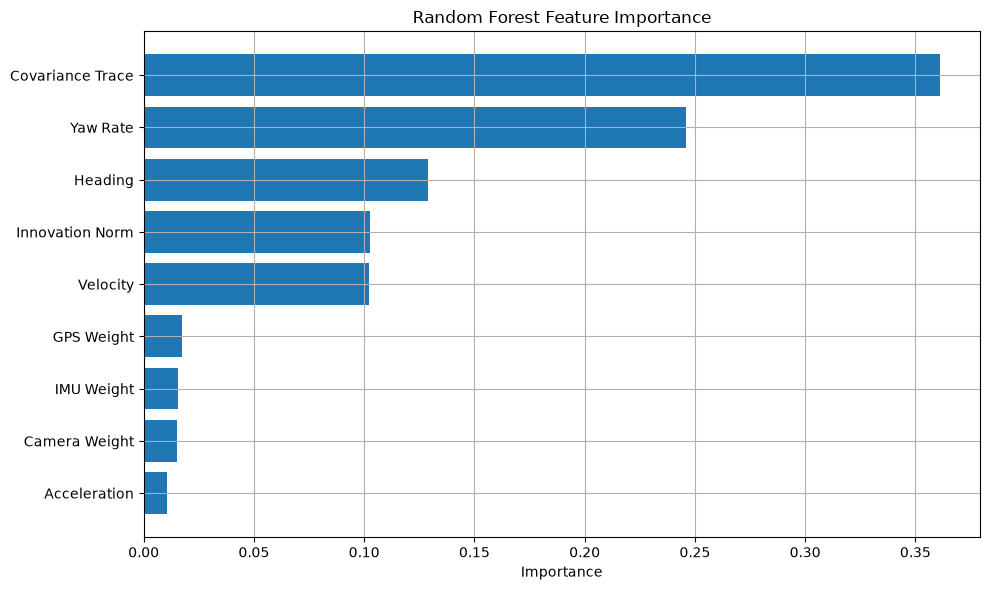

In [10]:
# ============================================================
# Cell 10
# Feature Importance
# ============================================================

importance = pd.DataFrame({

    "Feature": FEATURES,

    "Importance": rf_model.feature_importances_

})

importance = importance.sort_values(

    "Importance",

    ascending=False

)

display(importance)

plt.figure(figsize=(10,6))

plt.barh(

    importance["Feature"],

    importance["Importance"]

)

plt.gca().invert_yaxis()

plt.xlabel("Importance")

plt.title("Random Forest Feature Importance")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "feature_importance.png",

    dpi=300

)

plt.show()

In [11]:
# ============================================================
# Cell 11
# Prediction Results
# ============================================================

prediction = pd.DataFrame({

    "Actual": y_test.values,

    "Predicted": rf_prediction

})

prediction["Residual"] = (

    prediction["Actual"]

    -

    prediction["Predicted"]

)

display(

    prediction.head()

)

,Actual,Predicted,Residual
0,0.842607,0.825011,0.017596
1,0.512226,0.537886,-0.025660
2,0.663197,0.627691,0.035506
3,0.579439,0.575192,0.004247
4,0.661045,0.689622,-0.028577


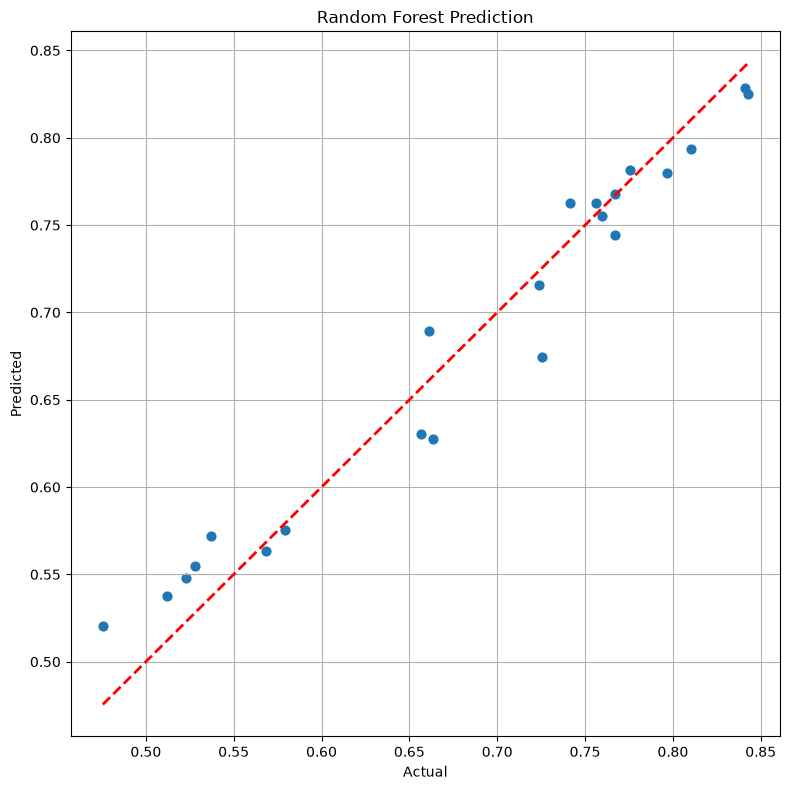

In [12]:
# ============================================================
# Cell 12
# Actual vs Predicted
# ============================================================

plt.figure(figsize=(8,8))

plt.scatter(

    prediction["Actual"],

    prediction["Predicted"],

    s=40

)

minimum = min(

    prediction["Actual"].min(),

    prediction["Predicted"].min()

)

maximum = max(

    prediction["Actual"].max(),

    prediction["Predicted"].max()

)

plt.plot(

    [minimum, maximum],

    [minimum, maximum],

    "r--",

    linewidth=2

)

plt.xlabel("Actual")

plt.ylabel("Predicted")

plt.title("Random Forest Prediction")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "prediction_vs_actual.png",

    dpi=300

)

plt.show()

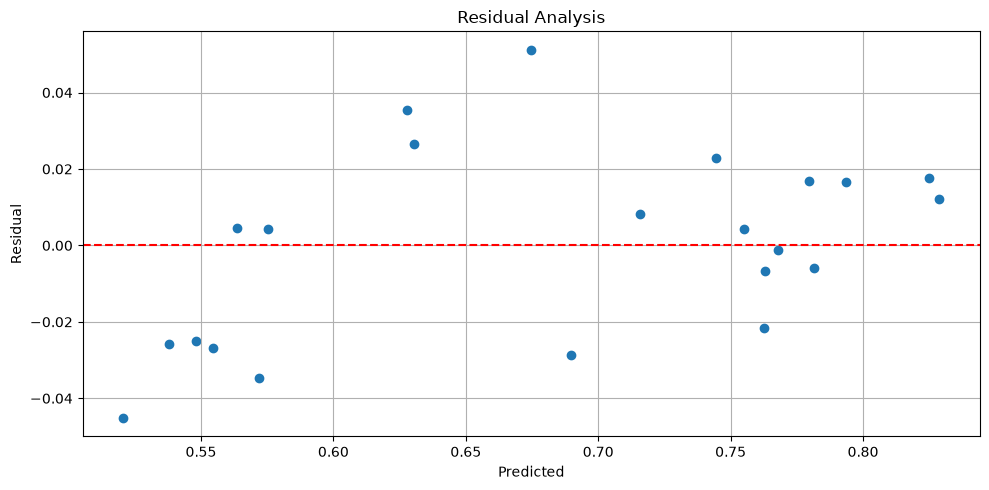

In [13]:
# ============================================================
# Cell 13
# Residual Analysis
# ============================================================

plt.figure(figsize=(10,5))

plt.scatter(

    prediction["Predicted"],

    prediction["Residual"]

)

plt.axhline(

    0,

    color="red",

    linestyle="--"

)

plt.xlabel("Predicted")

plt.ylabel("Residual")

plt.title("Residual Analysis")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "residual_plot.png",

    dpi=300

)

plt.show()

In [14]:
# ============================================================
# Cell 14
# Save Results
# ============================================================

joblib.dump(
    rf_model,
    MODEL_DIR / "localization_reliability_rf.joblib"
)

comparison.to_csv(
    RESULT_DIR / f"model_comparison_{DRIVE}.csv",
    index=False
)

importance.to_csv(
    RESULT_DIR / f"feature_importance_{DRIVE}.csv",
    index=False
)

prediction.to_csv(
    RESULT_DIR / f"localization_prediction_{DRIVE}.csv",
    index=False
)

print("="*80)
print("Results Saved Successfully")
print("="*80)

Results Saved Successfully


In [15]:
# ============================================================
# Cell 15
# Final Summary
# ============================================================

print("="*80)

print("NOTEBOOK 12 COMPLETED SUCCESSFULLY")

print("="*80)

print()

print("Drive :", DRIVE)

print()

print("Best Machine Learning Model")

print("----------------------------")

print(best_model)

print()

print("Performance")

print("----------------------------")

print(f"RMSE : {rf_rmse:.4f}")

print(f"MAE  : {rf_mae:.4f}")

print(f"R²   : {rf_r2:.4f}")

print()

print("Top Five Features")

print("----------------------------")

display(

    importance.head()

)

print()

print("Generated Model")

print("----------------------------")

print("localization_reliability_rf.joblib")

print()

print("Generated CSV Files")

print("----------------------------")

print(f"model_comparison_{DRIVE}.csv")

print(f"feature_importance_{DRIVE}.csv")

print(f"localization_prediction_{DRIVE}.csv")

print()

print("Generated Figures")

print("----------------------------")

print("feature_correlation_matrix.png")

print("feature_importance.png")

print("prediction_vs_actual.png")

print("residual_plot.png")

print()

print("="*80)

print("COMPLETE RESEARCH PIPELINE FINISHED")

print("="*80)

print()

print("Notebook 03 ✓ Dataset Loading")

print("Notebook 04 ✓ Camera Quality Metrics")

print("Notebook 05 ✓ Camera Confidence")

print("Notebook 06 ✓ Camera Reliability")

print("Notebook 07 ✓ GPS & IMU Quality")

print("Notebook 08 ✓ GPS & IMU Confidence")

print("Notebook 09 ✓ Adaptive Sensor Weight Generation")

print("Notebook 10 ✓ Confidence-Driven Sensor Fusion")

print("Notebook 11 ✓ Confidence-Driven Adaptive EKF")

print("Notebook 12 ✓ Learning-Based Localization Reliability Prediction")

print()

print("="*80)

print("READY FOR PAPER WRITING")

print("="*80)

NOTEBOOK 12 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync

Best Machine Learning Model
----------------------------
Random Forest

Performance
----------------------------
RMSE : 0.0242
MAE  : 0.0201
R²   : 0.9555

Top Five Features
----------------------------


,Feature,Importance
8,Covariance Trace,0.361231
3,Yaw Rate,0.246159
1,Heading,0.128974
7,Innovation Norm,0.102854
0,Velocity,0.102357



Generated Model
----------------------------
localization_reliability_rf.joblib

Generated CSV Files
----------------------------
model_comparison_2011_09_26_drive_0001_sync.csv
feature_importance_2011_09_26_drive_0001_sync.csv
localization_prediction_2011_09_26_drive_0001_sync.csv

Generated Figures
----------------------------
feature_correlation_matrix.png
feature_importance.png
prediction_vs_actual.png
residual_plot.png

COMPLETE RESEARCH PIPELINE FINISHED

Notebook 03 ✓ Dataset Loading
Notebook 04 ✓ Camera Quality Metrics
Notebook 05 ✓ Camera Confidence
Notebook 06 ✓ Camera Reliability
Notebook 07 ✓ GPS & IMU Quality
Notebook 08 ✓ GPS & IMU Confidence
Notebook 09 ✓ Adaptive Sensor Weight Generation
Notebook 10 ✓ Confidence-Driven Sensor Fusion
Notebook 11 ✓ Confidence-Driven Adaptive EKF
Notebook 12 ✓ Learning-Based Localization Reliability Prediction

READY FOR PAPER WRITING
